In [1]:
import sklearn.cluster
import scipy.spatial
import matplotlib


def cluster_trajs(trajs, n_clusters, cluster_centers):
    trajs_concat = np.concatenate(trajs)

    if cluster_centers is None:
        clustering_model = sklearn.cluster.KMeans(
            n_clusters=n_clusters,
            init="k-means++",
            n_init=10,
            max_iter=int(1e10),
            tol=1e-10,
            verbose=0,
            random_state=1,
            copy_x=True,
            algorithm="lloyd"
        )
        clustering_model.fit(trajs_concat)
        cluster_centers = clustering_model.cluster_centers_

    clustered_trajs_concat = scipy.spatial.cKDTree(cluster_centers).query(trajs_concat)[1]
    return clustered_trajs_concat.reshape(len(trajs), N_TIMESTEP_IN_REPLICA), cluster_centers


def plot_clusters_1d(ax, trajs, clustered_trajs, cluster_centers):
    trajs_concat = np.concatenate(trajs)
    clustered_trajs_concat = np.concatenate(clustered_trajs)

    ax.hist(trajs_concat, bins=n_clusters*5)
    for cluster_center in cluster_centers:
        ax.axvline(x=cluster_center, color="black", linewidth=0.2)


def plot_clusters_2d(ax, trajs, clustered_trajs, cluster_centers):
    trajs_concat = np.concatenate(trajs)
    clustered_trajs_concat = np.concatenate(clustered_trajs)

    ax.scatter(trajs_concat[:, 0], trajs_concat[:, 1], s=0.1, c=[matplotlib.cm.tab20(i_cluster%20) for i_cluster in clustered_trajs_concat])
    for cluster_center in cluster_centers:
        ax.scatter(cluster_center[0], cluster_center[1], color="black", s=5)

In [2]:
import deeptime.markov
import deeptime.markov.msm
import deeptime.util.validation
import deeptime.plots
from deeptime.markov._base import MembershipsObservable
from deeptime.util.validation import ChapmanKolmogorovTest
from matplotlib.lines import Line2D


def construct_msm(clustered_trajs, lagtimes):
    msm_models = {}
    stationary_distributions = {}

    for lagtime in lagtimes:
        count_estimator = deeptime.markov.TransitionCountEstimator(
            lagtime=lagtime,
            count_mode="sliding",
            n_states=None,
            sparse=False,
        )
        count_estimator.fit(clustered_trajs)
        count_model = count_estimator.fetch_model()

        msm_constructor = deeptime.markov.msm.MaximumLikelihoodMSM(
            reversible=True,
            stationary_distribution_constraint=None,
            sparse=False,
            allow_disconnected=False,
            maxiter=int(1e10),
            maxerr=1e-10,
            connectivity_threshold=0,
            transition_matrix_tolerance=1e-10,
            lagtime=None,
            use_lcc=True,
        ) 

        try:
            msm_constructor.fit(count_model)
        except Exception as e:
            print(f"MSM construction error lagtime {lagtime}: {e}")
            continue

        msm_models[lagtime] = msm_constructor.fetch_model()
        stationary_distributions[lagtime] = np.zeros(np.max(clustered_trajs)+1)
        stationary_distributions[lagtime][msm_models[lagtime].count_model.state_symbols] = msm_models[lagtime].stationary_distribution

    return msm_models, stationary_distributions


def plot_implied_timescales(ax, msm_models):
    deeptime.plots.plot_implied_timescales(
        data=deeptime.util.validation.implied_timescales(list(msm_models.values())),
        n_its=10,
        process=None,
        show_mle=True,
        show_samples=True,
        show_sample_mean=True,
        show_sample_confidence=True,
        show_cutoff=True,
        sample_confidence=0.95,
        colors=None,
        ax=ax
    )
    ax.set_xlim(0, np.max(list(msm_models.keys())))
    ax.set_yscale("log")


def perform_ck_test(clustered_trajs_reference, msm_models_reference, clustered_trajs_bootstrap, msm_models_bootstrap, lagtime, n_metastable_sets, conf=0.95, tolerance=0.05):
    def draw_ck_test(ck_test, is_markovian, conf=0.95):
        grid = deeptime.plots.plot_ck_test(ck_test, conf=conf, legend=False, y01=False, sharey=False)
        grid.figure.legend(
            handles=[Line2D([], [], color="black", label="estimate"), Line2D([], [], color="C0", ls="--", label="predict")],
            loc="upper center",
            ncols=2,
            frameon=False,
            title=f"Markovian: {is_markovian}"
        )
        plt.show()

    ck_models_reference, _ = construct_msm(clustered_trajs_reference, [lagtime*k for k in range(1, 5) if lagtime*k < N_TIMESTEP_IN_REPLICA - 1])
    ck_lagtimes = list(ck_models_reference)
    if len(ck_lagtimes) < 2:
        return None

    is_bootstrap = clustered_trajs_bootstrap is not None and msm_models_bootstrap is not None
    test_model_reference = msm_models_reference[lagtime]
    n_states_full = max(msm_models[lagtime].count_model.n_states_full for msm_models in [msm_models_reference, *(msm_models_bootstrap if is_bootstrap else [])])
    memberships = np.zeros((n_states_full, n_metastable_sets))
    memberships[test_model_reference.count_model.state_symbols] = test_model_reference.pcca(n_metastable_sets).memberships

    def calculate_ck_test(ck_models, msm_models):
        test_model = msm_models[lagtime]
        observable = MembershipsObservable(test_model, memberships[test_model.count_model.state_symbols])
        return deeptime.util.validation.ck_test([ck_models[ck_lagtime] for ck_lagtime in ck_lagtimes], observable, test_model=test_model)

    ck_test_reference = calculate_ck_test(ck_models_reference, msm_models_reference)
    checked = lagtime < ck_test_reference.lagtimes

    if not is_bootstrap:
        differences = np.real(ck_test_reference.predictions - ck_test_reference.estimates)[checked]
        passed = np.abs(differences) <= tolerance
        is_markovian = bool(np.all(passed))
        for i_lagtime, i, j in zip(*np.where(~passed)):
            print(f"lag {ck_test_reference.lagtimes[checked][i_lagtime]}: {i+1} -> {j+1}", f"predict-estimate: {differences[i_lagtime, i, j]:+.4f}")

        draw_ck_test(ck_test_reference, is_markovian)
        return is_markovian

    ck_tests_bootstrap = []
    for i_bootstrap, (clustered_trajs, msm_models) in enumerate(zip(clustered_trajs_bootstrap, msm_models_bootstrap)):
        ck_models, _ = construct_msm(clustered_trajs, ck_lagtimes)
        if all(ck_lagtime in ck_models for ck_lagtime in ck_lagtimes):
            ck_tests_bootstrap.append(calculate_ck_test(ck_models, msm_models))
        else:
            print(f"error bootstrap {i_bootstrap}, lag {ck_lagtimes}")
    if len(ck_tests_bootstrap) < 2:
        return None

    i_lagtimes = range(len(ck_test_reference.lagtimes))
    ck_test = ChapmanKolmogorovTest(
        ck_test_reference.lagtimes,
        ck_test_reference.predictions,
        [[ck_test_bootstrap.predictions[i_lagtime] for ck_test_bootstrap in ck_tests_bootstrap] for i_lagtime in i_lagtimes],
        ck_test_reference.estimates,
        [[ck_test_bootstrap.estimates[i_lagtime] for ck_test_bootstrap in ck_tests_bootstrap] for i_lagtime in i_lagtimes],
        None,
    )

    differences = np.real(np.array(ck_test.predictions_samples) - np.array(ck_test.estimates_samples))[checked]
    with np.errstate(invalid="ignore"):
        differences_lower, differences_upper = np.nanpercentile(differences, [50*(1-conf), 50*(1+conf)], axis=1)
    passed = (differences_lower <= tolerance) & (-tolerance <= differences_upper)
    passed |= np.isnan(differences_lower)
    is_markovian = bool(np.all(passed))
    for i_lagtime, i, j in zip(*np.where(~passed)):
        print(
            f"lag {ck_test.lagtimes[checked][i_lagtime]}: {i+1} -> {j+1}",
            f"predict-estimate: [{differences_lower[i_lagtime, i, j]:+.4f}, {differences_upper[i_lagtime, i, j]:+.4f}]"
        )

    draw_ck_test(ck_test, is_markovian, conf=conf)
    return is_markovian

In [3]:
import scipy.constants
from deeptime.util import energy2d
from scipy.spatial import Voronoi


def plot_energy_landscape(ax, msm_model, trajs, clustered_trajs):
    kbt = scipy.constants.Boltzmann
    kbt *= TEMPERATURE
    kbt *= scipy.constants.Avogadro
    kbt /= scipy.constants.calorie
    kbt /= 1000
    
    weights = msm_model.compute_trajectory_weights(np.concatenate(clustered_trajs))[0]
    energies = energy2d(*np.concatenate(trajs).T, bins=(50, 50), kbt=kbt, weights=weights, shift_energy=True)
    
    ax, contour, cbar = energies.plot(contourf_kws=dict(cmap="nipy_spectral"), ax=ax)
    ax.grid(True, color="black", alpha=0.3)
    ax.set_aspect("equal", adjustable="box")

    return energies, cbar


def compute_metastable_states(msm_model, n_metastable_sets, trajs_concat, clustered_trajs_concat):
    pcca = msm_model.pcca(n_metastable_sets=n_metastable_sets)

    metastable_states_cluster = np.full(np.max(clustered_trajs_concat) + 1, -1)
    metastable_states_cluster[msm_model.count_model.state_symbols] = np.argmax(pcca.memberships, axis=1)
    metastabled_trajs_concat = metastable_states_cluster[clustered_trajs_concat]

    boundary_lines = []
    voronoi = Voronoi(trajs_concat)
    for (p1, p2), ridge_vertices in zip(voronoi.ridge_points, voronoi.ridge_vertices):
        if -1 in ridge_vertices:
            continue
        if metastabled_trajs_concat[p1] != metastabled_trajs_concat[p2]:
            v0, v1 = voronoi.vertices[ridge_vertices]
            boundary_lines.append(((v0[0], v1[0]), (v0[1], v1[1])))

    return pcca, metastabled_trajs_concat, boundary_lines

def plot_metastable_states(ax, trajs_concat, metastabled_trajs_concat, color_sequence=None):
    colors = [matplotlib.cm.tab10(int(metastable_state_index)%10) for metastable_state_index in metastabled_trajs_concat]
    if color_sequence != None:
        colors = [color_sequence[int(metastable_state_index)] for metastable_state_index in metastabled_trajs_concat]
    ax.scatter(*trajs_concat.T, color=colors, s=0.1)

    ax.grid(True, color="black", alpha=0.3)
    ax.set_aspect("equal", adjustable="box")


def plot_voronoi_boundary(ax, boundary_lines):
    for p1, p2 in boundary_lines:
        ax.plot(p1, p2, color="black", linewidth=1)

In [4]:
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt
import os
import pickle


N_TIMESTEP_IN_REPLICA = 18000
N_TIMESTEP_IN_REPLICA_PACS = 101
TEMPERATURE = 300

pickle_dir = "./pickle-cache/pca_protein_all"
if not os.path.exists(pickle_dir):
    os.mkdir(pickle_dir)

gleap_target = md.load("../20250801_FUS-RRM/2_md-preparation-2/gleap.target.gro")
atom_indices_protein = gleap_target.topology.select("resid 23 to 126")
atom_indices_rna     = gleap_target.topology.select("resid  0 to  22")


xtcs_cmd = []
for trial in range(5):
    xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)[2001:]
    print(trial, xtc.n_frames)
    xtc = xtc.superpose(gleap_target, atom_indices=atom_indices_protein, ref_atom_indices=atom_indices_protein)
    xtcs_cmd.append(xtc)

pdbs_nmr = md.load("../20250801_FUS-RRM/1_modelling/1_6gbm.pdb")


atom_indices_gleap = [atom.index for atom in gleap_target.topology.atoms if 24<=atom.residue.index<=125]
print(len(atom_indices_gleap))
atom_indices_nmr = [atom.index for atom in pdbs_nmr.topology.atoms if 0<=atom.residue.index<=101]
print(len(atom_indices_nmr))

atom_vectors_cmd = [xtc.xyz[:, atom_indices_gleap, :].reshape(xtc.n_frames, len(atom_indices_gleap)*3) for xtc in xtcs_cmd]
atom_vectors_nmr = [pdb.xyz[:, atom_indices_nmr,   :].reshape(pdb.n_frames, len(atom_indices_nmr)  *3) for pdb in pdbs_nmr]


if False:
    pca = sklearn.decomposition.PCA(n_components=2, svd_solver="full")
    pca.fit(np.concatenate(atom_vectors_cmd)[::10])
    pickle.dump(pca, open(f"{pickle_dir}/pca.pickle", "wb"))

pca = pickle.load(open(f"{pickle_dir}/pca.pickle", "rb"))
print(pca.explained_variance_ratio_)


trajs = [np.array([pca.transform(_av) for _av in atom_vectors_cmd])]
for i_bootstrap in range(10):
    _traj = []
    for trial in np.random.default_rng(i_bootstrap).choice(len(atom_vectors_cmd), len(atom_vectors_cmd), replace=True):
        _traj.append(pca.transform(atom_vectors_cmd[trial]))
    trajs.append(np.array(_traj))

0 18000
1 18000
2 18000
3 18000
4 18000


/work18/kijima/programs/anaconda3/envs/jupyter/lib/python3.10/site-packages/mdtraj/formats/pdb/pdbfile.py:206: UserWarning: Unlikely unit cell vectors detected in PDB file likely resulting from a dummy CRYST1 record. Discarding unit cell vectors.
  warnings.warn(


1564
1564
[0.19372246 0.1428348 ]


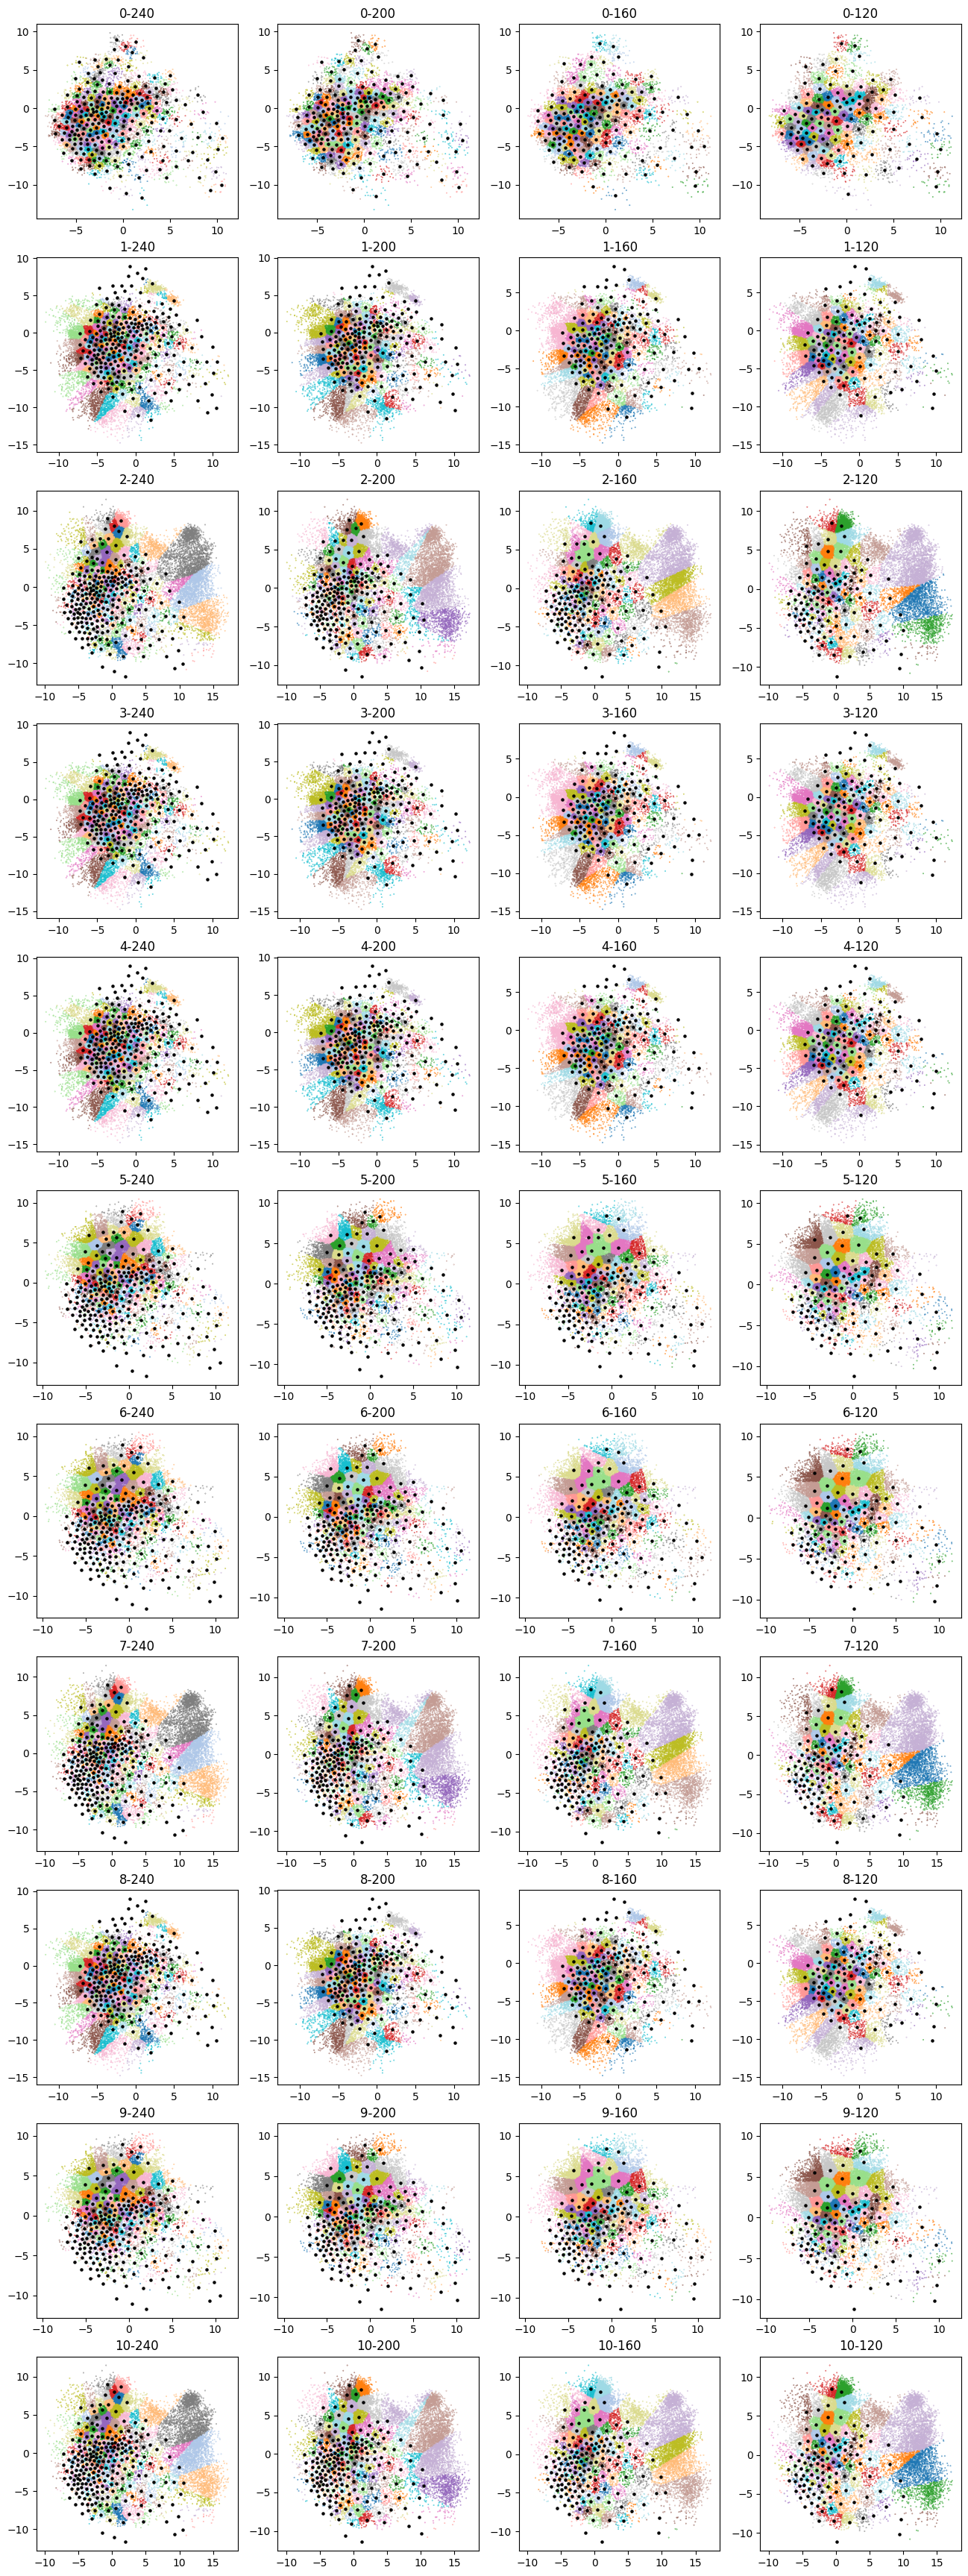

In [5]:
n_clusters_candidates = [240, 200, 160, 120]

if False:
    _cluster_centers = {}
    for i_clusters, n_clusters in enumerate(n_clusters_candidates):
        print("init", n_clusters)
        _, _cluster_centers[n_clusters] = cluster_trajs(trajs[0][::10], n_clusters, None)

    clustered_trajs = [None for _ in range(len(trajs))]
    cluster_centers = [None for _ in range(len(trajs))]

    for trial in range(len(trajs)):
        clustered_trajs[trial] = {}
        cluster_centers[trial] = {}
        for i_clusters, n_clusters in enumerate(n_clusters_candidates):
            print(trial, n_clusters)
            clustered_trajs[trial][n_clusters], cluster_centers[trial][n_clusters] = cluster_trajs(trajs[trial], n_clusters, _cluster_centers[n_clusters])

    pickle.dump(clustered_trajs, open(f"{pickle_dir}/clustered_trajs.pickle", "wb"))
    pickle.dump(cluster_centers, open(f"{pickle_dir}/cluster_centers.pickle", "wb"))
else:
    clustered_trajs = pickle.load(open(f"{pickle_dir}/clustered_trajs.pickle", "rb"))
    cluster_centers = pickle.load(open(f"{pickle_dir}/cluster_centers.pickle", "rb"))


fig, ax = plt.subplots(len(trajs), len(n_clusters_candidates))
fig.set_size_inches(len(n_clusters_candidates)*4, len(trajs)*4)

for trial in range(len(trajs)):
    for i_clusters, n_clusters in enumerate(n_clusters_candidates):
        plot_clusters_2d(ax[trial][i_clusters], trajs[trial][::10], clustered_trajs[trial][n_clusters][::10], cluster_centers[trial][n_clusters])
        ax[trial][i_clusters].set_title(f"{trial}-{n_clusters}")

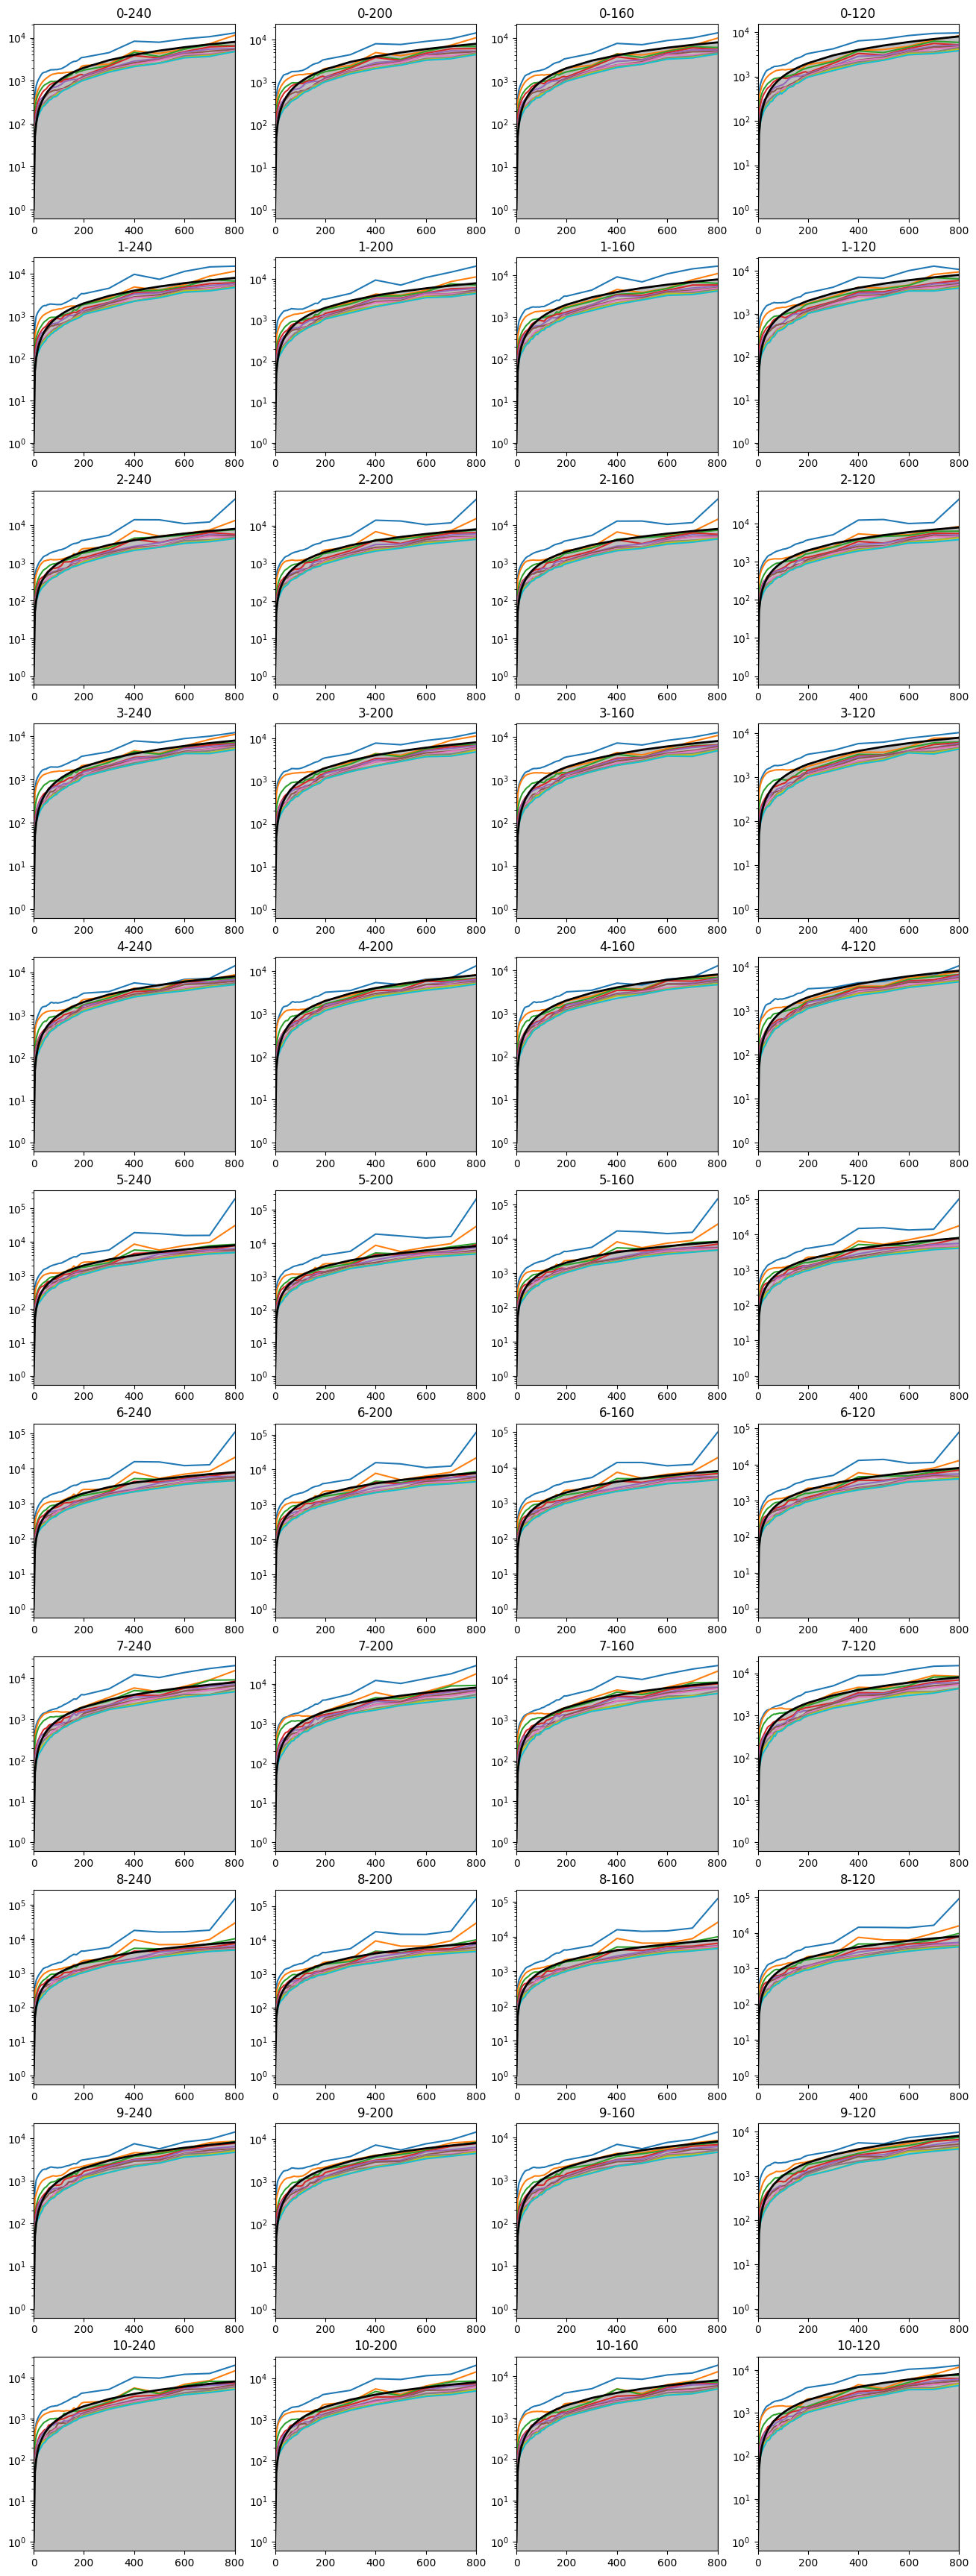

In [17]:
if False:
    lagtimes = [1] + list(range(50, 1001, 50)) + list(range(1000, 2001, 100)) + list(range(2000, int(N_TIMESTEP_IN_REPLICA/2), 1000))
    msm_models = [None for _ in range(len(trajs))]
    stationary_distributions = [None for _ in range(len(trajs))]

    for trial in range(len(trajs)):
        msm_models[trial] = {}
        stationary_distributions[trial] = {}
        for i_clusters, n_clusters in enumerate(n_clusters_candidates):
            print(trial, n_clusters)
            msm_models[trial][n_clusters], stationary_distributions[trial][n_clusters] = construct_msm(clustered_trajs[trial][n_clusters], lagtimes)

    pickle.dump(msm_models, open(f"{pickle_dir}/msm_models.pickle", "wb"))
    pickle.dump(stationary_distributions, open(f"{pickle_dir}/stationary_distributions.pickle", "wb"))
else:
    msm_models = pickle.load(open(f"{pickle_dir}/msm_models.pickle", "rb"))
    stationary_distributions = pickle.load(open(f"{pickle_dir}/stationary_distributions.pickle", "rb"))


fig, ax = plt.subplots(len(trajs), len(n_clusters_candidates))
fig.set_size_inches(len(n_clusters_candidates)*4, len(trajs)*4)

for trial in range(len(trajs)):
    for i_clusters, n_clusters in enumerate(n_clusters_candidates):
        plot_implied_timescales(ax[trial][i_clusters], msm_models[trial][n_clusters])
        ax[trial][i_clusters].set_xticks(range(0, 8001, 2000), range(0, 801, 200))
        ax[trial][i_clusters].set_title(f"{trial}-{n_clusters}")

In [7]:
for trial in range(len(trajs)):
    for n_clusters in msm_models[trial]:
        for lagtime in msm_models[trial][n_clusters]:
            if not deeptime.markov.tools.analysis.is_reversible(msm_models[trial][n_clusters][lagtime].transition_matrix, mu=None, tol=1e-12):
                print(trial, n_clusters, lagtime)

In [8]:
# n_metastable_sets = 2
# for n_clusters in msm_models[0]:
#     for lagtime in msm_models[0][n_clusters]:
#         print(n_clusters, lagtime, perform_ck_test(clustered_trajs[0][n_clusters], msm_models[0][n_clusters], [clustered_trajs[i][n_clusters] for i in range(1, len(clustered_trajs))], [msm_models[i][n_clusters] for i in range(1, len(msm_models))], lagtime, n_metastable_sets))

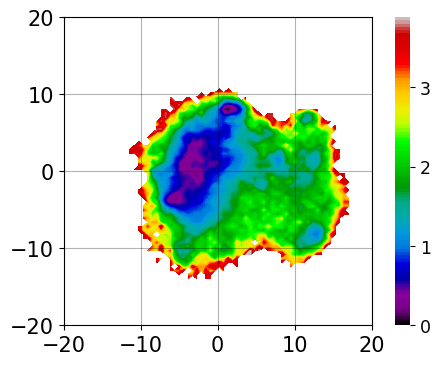

In [9]:
N_CLUSTERS = 160
LAGTIME = 1900

fig, ax = plt.subplots(1, 1)
fig.set_size_inches(6, 4)

energies, cbar = plot_energy_landscape(ax, msm_models[0][N_CLUSTERS][LAGTIME], trajs[0], clustered_trajs[0][N_CLUSTERS])
cbar.set_ticks(ticks=[0, 1, 2, 3], labels=[0, 1, 2, 3], size=12.5)

ax.set_xlim(-20, 20)
ax.set_ylim(-20, 20)

ax.set_xticks(range(-20, 21, 10))
ax.set_yticks(range(-20, 21, 10))

ax.tick_params(axis="x", labelsize=15)
ax.tick_params(axis="y", labelsize=15)

In [10]:
e_min_0 = 10000
e_min_1 = 10000

for i_x, x in enumerate(energies.x_meshgrid):
    for i_y, y in enumerate(energies.y_meshgrid):
        e = energies.energies[i_y, i_x]
        if x < 0 and e < e_min_0:
            e_min_0 = e
        elif x > 0 and e < e_min_1:
            e_min_1 = e

print(e_min_0, e_min_1)

0.17350738845724925 0.0


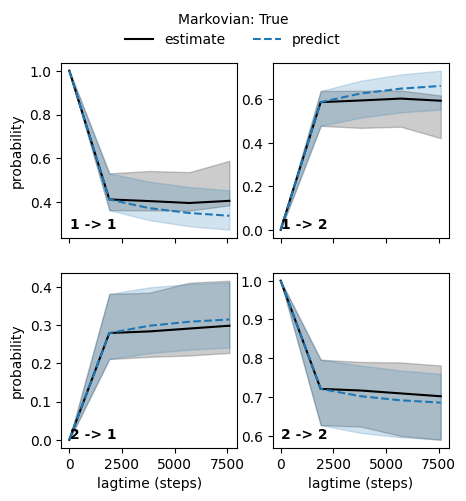

True

In [11]:
n_metastable_sets = 2
perform_ck_test(clustered_trajs[0][N_CLUSTERS], msm_models[0][N_CLUSTERS], [clustered_trajs[i][N_CLUSTERS] for i in range(1, len(clustered_trajs))], [msm_models[i][N_CLUSTERS] for i in range(1, len(msm_models))], LAGTIME, n_metastable_sets)

[[0.70167437 0.29832563]
 [0.14179626 0.85820374]]
[0.32217498 0.67782502]
13399.507077333552
6368.879533616317



(<Axes: xlabel='Committor probability'>,
 array([[0., 0.],
        [1., 1.]], dtype=float32))

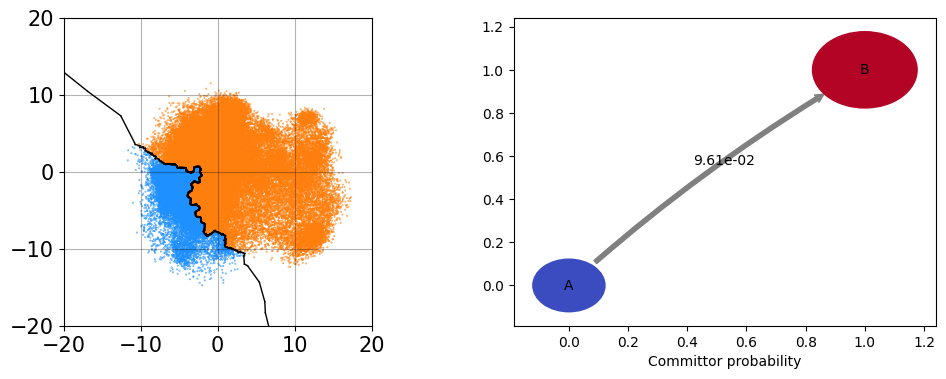

In [12]:
import os
from deeptime.markov.tools.analysis import mfpt


fig, ax = plt.subplots(1, 2)
fig.set_size_inches(12, 4)

n_metastable_sets = 2
pcca, metastabled_trajs_concat, boundary_lines = compute_metastable_states(msm_models[0][N_CLUSTERS][LAGTIME], n_metastable_sets, np.concatenate(trajs[0]), np.concatenate(clustered_trajs[0][N_CLUSTERS]))
pickle.dump(metastabled_trajs_concat, open(f"{pickle_dir}/metastabled_trajs_concat_{n_metastable_sets}.pickle", "wb"))
pickle.dump(boundary_lines,           open(f"{pickle_dir}/boundary_lines_{n_metastable_sets}.pickle", "wb"))
plot_metastable_states(ax[0], np.concatenate(trajs[0]), metastabled_trajs_concat, color_sequence=["#1E90FF", "tab:orange"])
plot_voronoi_boundary(ax[0], boundary_lines)

print(pcca.coarse_grained_transition_matrix)
print(pcca.coarse_grained_stationary_probability)
print(mfpt(T=pcca.coarse_grained_transition_matrix, target=[0], origin=[1], tau=LAGTIME, mu=pcca.coarse_grained_stationary_probability))
print(mfpt(T=pcca.coarse_grained_transition_matrix, target=[1], origin=[0], tau=LAGTIME, mu=pcca.coarse_grained_stationary_probability))
print()

ax[0].set_xlim(-20, 20)
ax[0].set_ylim(-20, 20)

ax[0].set_xticks(range(-20, 21, 10))
ax[0].set_yticks(range(-20, 21, 10))

ax[0].tick_params(axis="x", labelsize=15)
ax[0].tick_params(axis="y", labelsize=15)


transition_matrix = np.maximum(pcca.coarse_grained_transition_matrix, 0)
transition_matrix /= transition_matrix.sum(axis=1, keepdims=True)

flux = deeptime.markov.msm.MarkovStateModel(transition_matrix).reactive_flux([0], [1])
deeptime.plots.plot_flux(flux, ax=ax[1])

In [14]:
tmp = []
for trial in range(5):
    xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)[2001:][::10]
    tmp.append(xtc)
xtc_tmp = md.join(tmp)
traj_tmp = pca.transform(xtc_tmp.xyz[:, atom_indices_gleap, :].reshape(xtc_tmp.n_frames, len(atom_indices_gleap)*3))

xtc_tmp[metastabled_trajs_concat[::10]==0].save_xtc("pca_protein_all/0.xtc")
xtc_tmp[metastabled_trajs_concat[::10]==1].save_xtc("pca_protein_all/1.xtc")

xtc_tmp[np.argmin(np.abs(np.linalg.norm(traj_tmp-(-7, -5), axis=1)))].save_gro("pca_protein_all/0.gro")
xtc_tmp[np.argmin(np.abs(np.linalg.norm(traj_tmp-(-5, 0), axis=1)))].save_gro("pca_protein_all/1.gro")
xtc_tmp[np.argmin(np.abs(np.linalg.norm(traj_tmp-(5, 7), axis=1)))].save_gro("pca_protein_all/2.gro")

In [15]:
for pc1 in [-10, -5, 0, 5, 10]:
    snapshots = []
    for pc2 in [-10, -5, 0, 5, 10]:
        snapshots.append(xtc_tmp[np.argmin(np.abs(np.linalg.norm(traj_tmp-(pc1, pc2), axis=1)))])
    md.join(snapshots).save_xtc(f"pca_protein_all/pc1_{pc1}.xtc")

for pc2 in [-10, -5, 0, 5, 10]:
    snapshots = []
    for pc1 in [-10, -5, 0, 5, 10]:
        snapshots.append(xtc_tmp[np.argmin(np.abs(np.linalg.norm(traj_tmp-(pc1, pc2), axis=1)))])
    md.join(snapshots).save_xtc(f"pca_protein_all/pc2_{pc2}.xtc")

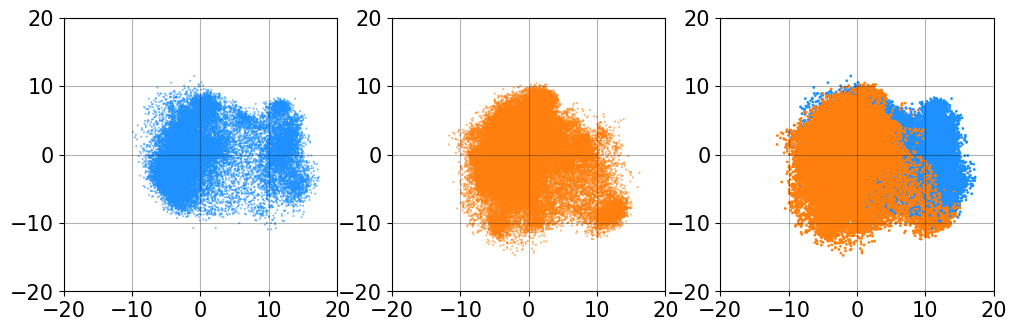

In [19]:
fig, ax = plt.subplots(1, 3)
fig.set_size_inches(12, 4)


metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/pca_tetranucl_all/metastabled_trajs_concat_2.pickle", "rb"))

colors = ["#1E90FF", "tab:orange"]
trajs_concat = np.concatenate(trajs[0])
ax[0].scatter(trajs_concat[metastabled_trajs_concat==0, 0], trajs_concat[metastabled_trajs_concat==0, 1], c=[colors[state%2] for state in metastabled_trajs_concat if state==0], s=0.1)
ax[1].scatter(trajs_concat[metastabled_trajs_concat==1, 0], trajs_concat[metastabled_trajs_concat==1, 1], c=[colors[state%2] for state in metastabled_trajs_concat if state==1], s=0.1)
ax[2].scatter(trajs_concat[:, 0], trajs_concat[:, 1], c=[colors[state%2] for state in metastabled_trajs_concat], s=1)

for i_ax in range(3):
    ax[i_ax].set_xlim(-20, 20)
    ax[i_ax].set_ylim(-20, 20)
    
    ax[i_ax].set_xticks(range(-20, 21, 10))
    ax[i_ax].set_yticks(range(-20, 21, 10))
    ax[i_ax].tick_params(axis="x", labelsize=15)
    ax[i_ax].tick_params(axis="y", labelsize=15)
    
    ax[i_ax].grid(True, color="black", alpha=0.3)
    ax[i_ax].set_aspect("equal", adjustable="box")